# Week 5 Checkpoint: Explainable Baseline for Phishing Detection

**Goal:** Establish a highly explainable baseline model (Logistic Regression with TF-IDF) to detect phishing emails.
Explainability is essential in security operations because analysts must justify why an email was flagged before escalating or blocking it.

**Dataset Selection:** We are using the *Naser Abdullah Alam Phishing Email Dataset* (~82,000 emails). This dataset was chosen because:
1. **Raw Text Availability:** It contains the raw email bodies, which is mandatory for extracting and visualizing specific "trigger words" for explainability.
2. **Class Balance:** With an almost 50/50 split of legitimate vs. phishing emails, we bypass the need for synthetic data generation (SMOTE), allowing us to focus strictly on explainability and model comparison.

In [1]:
import kagglehub
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# download the dataset
print("Downloading dataset...")
path = kagglehub.dataset_download("naserabdullahalam/phishing-email-dataset")
print(f"Dataset downloaded to: {path}")

# load the main combined file
df = pd.read_csv(f"{path}/phishing_email.csv")

# quick inspection
print(f"Dataset Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print("\nLabel distribution (0 = Legitimate, 1 = Phishing):\n", df['label'].value_counts(normalize=True))
display(df.head())

Dataset downloaded to: /Users/vipin/.cache/kagglehub/datasets/naserabdullahalam/phishing-email-dataset/versions/1
Dataset Shape: (82486, 2)
Columns: ['text_combined', 'label']

Label distribution (0 = Legitimate, 1 = Phishing):
 label
1    0.519979
0    0.480021
Name: proportion, dtype: float64


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


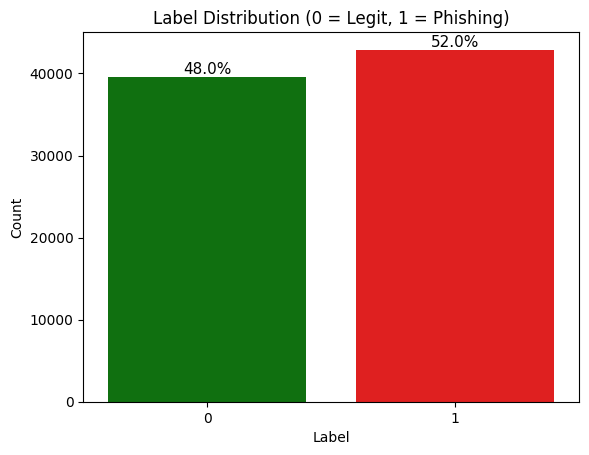

In [2]:
# visualize class balance
# countplot with explicit hue and custom colors
ax = sns.countplot(
    data=df,
    x='label',
    hue='label',
    palette={0: 'green', 1: 'red'},
    legend=False
)

# add percentage labels on top of each bar
total = len(df)
for p in ax.patches:
    count = p.get_height()
    percent = 100 * count / total
    ax.annotate(f'{percent:.1f}%',
                (p.get_x() + p.get_width() / 2., count),
                ha='center', va='bottom', fontsize=11)

plt.title("Label Distribution (0 = Legit, 1 = Phishing)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()


## 1. Data Cleaning and Preprocessing

Raw email data is incredibly noisy. HTML tags, obfuscated URLs, and erratic whitespace can ruin the TF-IDF feature space. By stripping HTML, normalizing URLs to a standard token (`URL`), lowercasing the text, and removing non-ASCII characters, we ensure our model learns actual linguistic patterns rather than noise.

We also drop any rows with missing text, as an empty string provides no features for NLP.

In [3]:
import re

# rename columns for consistency
df = df.rename(columns={'text_combined': 'text'})

# keep only text and label
df = df[['text', 'label']].copy()

# drop missing text
df = df.dropna(subset=['text'])

# text Cleaning Pipeline
print("Cleaning text data (this may take a minute)...")
# remove HTML tags
df['text'] = df['text'].str.replace(r'<.*?>', ' ', regex=True)
# normalize URLs (replace all links with the word 'URL')
df['text'] = df['text'].str.replace(r'http\S+', ' URL ', regex=True)
# clean extra whitespace
df['text'] = df['text'].str.replace(r'\s+', ' ', regex=True).str.strip()
# lowercase everything
df['text'] = df['text'].str.lower()
# remove non‑ASCII characters
df['text'] = df['text'].str.replace(r'[^\x00-\x7F]+', ' ', regex=True)


print(f"Cleaned dataset shape: {df.shape}")

Cleaning text data (this may take a minute)...
Cleaned dataset shape: (82486, 2)


count    8.248600e+04
mean     1.198108e+03
std      1.546287e+04
min      0.000000e+00
25%      2.670000e+02
50%      5.380000e+02
75%      1.302000e+03
max      4.275826e+06
Name: text_length, dtype: float64


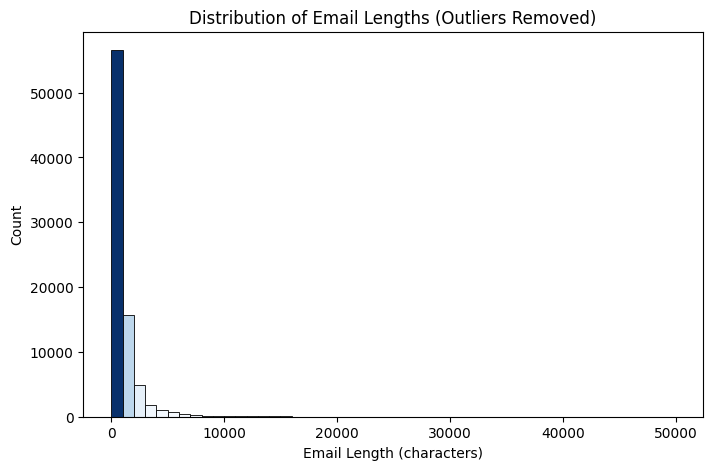

In [4]:
# exploratory analysis: Email length
df['text_length'] = df['text'].str.len()
print(df['text_length'].describe())

# remove emails longer than 50k chars
df = df[df['text_length'] < 50000]

# compute histogram
counts, bins = np.histogram(df['text_length'], bins=50)

# normalize counts for color mapping
norm = counts / counts.max()

plt.figure(figsize=(8, 5))

for i in range(len(counts)):
    plt.bar(
        bins[i],
        counts[i],
        width=bins[i+1] - bins[i],
        color=plt.cm.Blues(norm[i]),   # gradient shading
        edgecolor='black',
        linewidth=0.6,
        align='edge'
    )

plt.title("Distribution of Email Lengths (Outliers Removed)")
plt.xlabel("Email Length (characters)")
plt.ylabel("Count")
plt.show()

Phishing emails often tend to be shorter and more direct, while legitimate emails may be longer and more detailed. This distribution helps us understand whether length could be a weak signal for classification.

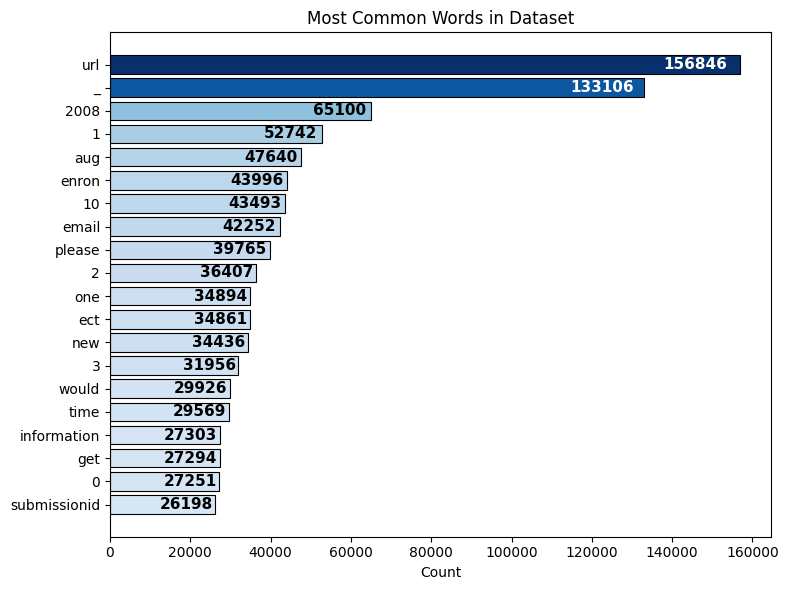

In [5]:
# exploratory analysis: most common words
from collections import Counter

all_words = " ".join(df['text']).split()
word_freq = Counter(all_words).most_common(20)

# unpack words and counts
words, counts = zip(*word_freq)

# normalize counts for gradient shading
norm = np.array(counts) / max(counts)

plt.figure(figsize=(8, 6))

for i, (word, count) in enumerate(zip(words, counts)):
    color = plt.cm.Blues(norm[i])   # gradient shading

    # draw bar
    plt.barh(
        word,
        count,
        color=color,
        edgecolor='black',
        linewidth=0.8
    )

    # choose text color based on bar shade
    text_color = "white" if norm[i] > 0.5 else "black"

    # insert count label inside the bar
    plt.text(
        count * 0.98,   # slightly inside the bar
        word,
        str(count),
        va='center',
        ha='right',
        color=text_color,
        fontsize=11,
        fontweight='bold'
    )

plt.title("Most Common Words in Dataset")
plt.xlabel("Count")
plt.gca().invert_yaxis()  # highest count at top
plt.tight_layout()
plt.show()


Because analysts must justify alerts, explainability is not optional, it is a functional requirement.

**Threat Model**

Phishing emails typically aim for:

* Credential theft

* Malware delivery

* Social engineering–based manipulation

In a security operations context:

* False positives → increase analyst alert fatigue

* False negatives → allow real attacks to slip through

Because of this, both precision (confidence when flagging threats) and recall (ability to catch threats) are critical.

This threat model motivates using a TF‑IDF and Logistic Regression baseline, which is explainable and provides interpretable decision boundaries.

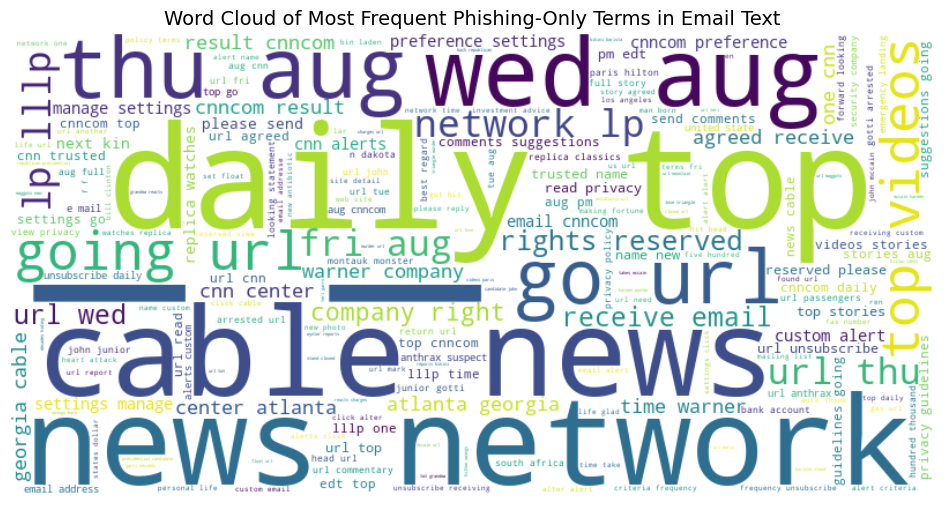

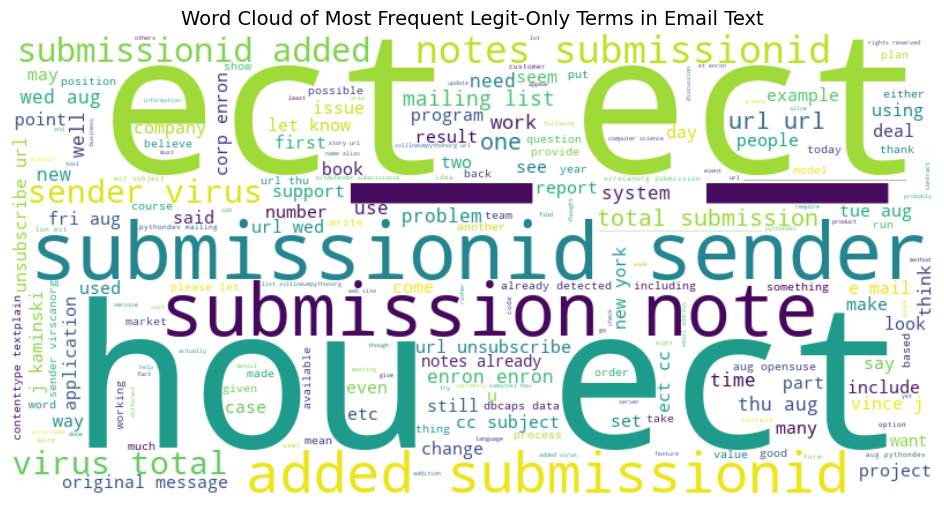

In [6]:
from wordcloud import WordCloud

phish_text = " ".join(df[df['label'] == 1]['text'])
legit_text = " ".join(df[df['label'] == 0]['text'])

# generate word cloud
wc_phish = WordCloud(width=800, height=400, background_color='white').generate(phish_text)
wc_legit = WordCloud(width=800, height=400, background_color='white').generate(legit_text)

# plot word cloud
plt.figure(figsize=(12, 6))
plt.imshow(wc_phish, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Most Frequent Phishing-Only Terms in Email Text", fontsize=14)
plt.show()

plt.figure(figsize=(12, 6))
plt.imshow(wc_legit, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Most Frequent Legit-Only Terms in Email Text", fontsize=14)
plt.show()


## 2. Text Vectorization & Train-Test Split

TF-IDF (Term Frequency-Inverse Document Frequency) converts text into numbers while down-weighting overly common words (like "the" or "and").
* `ngram_range=(1,2)` captures both single words ("urgent") and bigrams ("click here").
* `sublinear_tf=True` scales term frequency logarithmically, which is best practice for email length distributions.

We split the data using `stratify=y` to ensure the exact ratio of phishing-to-legitimate emails is preserved in both sets.
TF‑IDF is chosen for Week 5 because it is interpretable and computationally cheap, making it ideal as a baseline before introducing deep learning models in Week 7.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
import time

start = time.time()

# initialize Vectorizer
vectorizer = TfidfVectorizer(
    max_features=10000,      # cap vocabulary to top 10k words/phrases
    stop_words='english',    # remove standard English filler words
    ngram_range=(1, 2),      # capture unigrams and bigrams
    min_df=5,                # ignore words that appear in fewer than 5 emails
    max_df=0.95,             # ignore words that appear in >95% of emails
    sublinear_tf=True        # logarithmic scaling
)

print("Vectorizing text...")
X = vectorizer.fit_transform(df['text'])
y = df['label'].values

# split Data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"TF-IDF matrix shape: {X.shape}")
print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")
print(f"Vectorization time: {time.time() - start:.2f} seconds")

Vectorizing text...
TF-IDF matrix shape: (82430, 10000)
Train shape: (65944, 10000) | Test shape: (16486, 10000)
Vectorization time: 12.39 seconds


## 3. Training the Explainable Baseline

We use **Logistic Regression** here because its coefficients are mathematically transparent. For every feature (word/phrase) in our vocabulary, the model assigns a weight. A positive weight pushes the prediction toward "Phishing", and a negative weight pushes it toward "Legitimate".

We use the `liblinear` solver, which is highly optimized for sparse datasets like TF-IDF matrices.

In [8]:
from sklearn.linear_model import LogisticRegression

start = time.time()
print("Training Logistic Regression baseline...")

# create the model
model = LogisticRegression(
    max_iter=1000,
    solver='liblinear', # standard solver for text classification
    random_state=42
)

model.fit(X_train, y_train)

print(f"Model trained in {time.time() - start:.2f} seconds")

Training Logistic Regression baseline...
Model trained in 0.48 seconds


## 4. Evaluation: The Cost of Alert Fatigue

In cybersecurity, metrics must be tied to operational reality.
* **Precision:** If the model flags an email, how likely is it actually phishing? High precision minimizes "alert fatigue" for users/analysts.
* **Recall:** Out of all real phishing emails, how many did we catch? High recall minimizes security breaches.

Phishing Detection Metrics:
Precision: 0.9834 (Confidence when flagging)
Recall:    0.9899 (Proportion of threats caught)
ROC-AUC:   0.9988



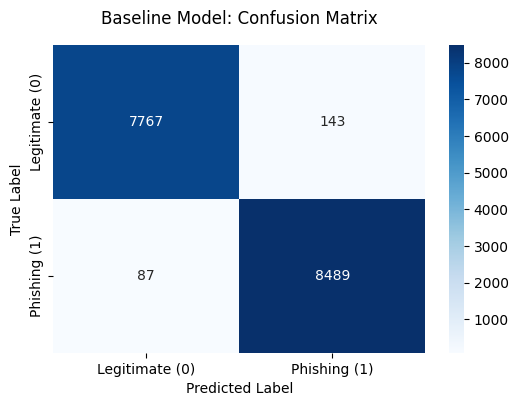

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, roc_auc_score
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)
y_probs = model.predict_proba(X_test)[:, 1]

# security-specific metrics
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, pos_label=1, average='binary'
)

roc_auc = roc_auc_score(y_test, y_probs)

print(f"Phishing Detection Metrics:")
print(f"Precision: {precision:.4f} (Confidence when flagging)")
print(f"Recall:    {recall:.4f} (Proportion of threats caught)")
print(f"ROC-AUC:   {roc_auc:.4f}\n")

# storytelling with Data: Visualizing the Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate (0)', 'Phishing (1)'],
            yticklabels=['Legitimate (0)', 'Phishing (1)'])
plt.title('Baseline Model: Confusion Matrix', pad=15)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

## 5. Explainability: Visualizing the "Trigger" Words

To satisfy the core goal of this project, we must understand *why* the model makes its decisions. By extracting the highest and lowest coefficients, we can visualize the exact vocabulary that triggers a phishing alert versus what constitutes normal correspondence.

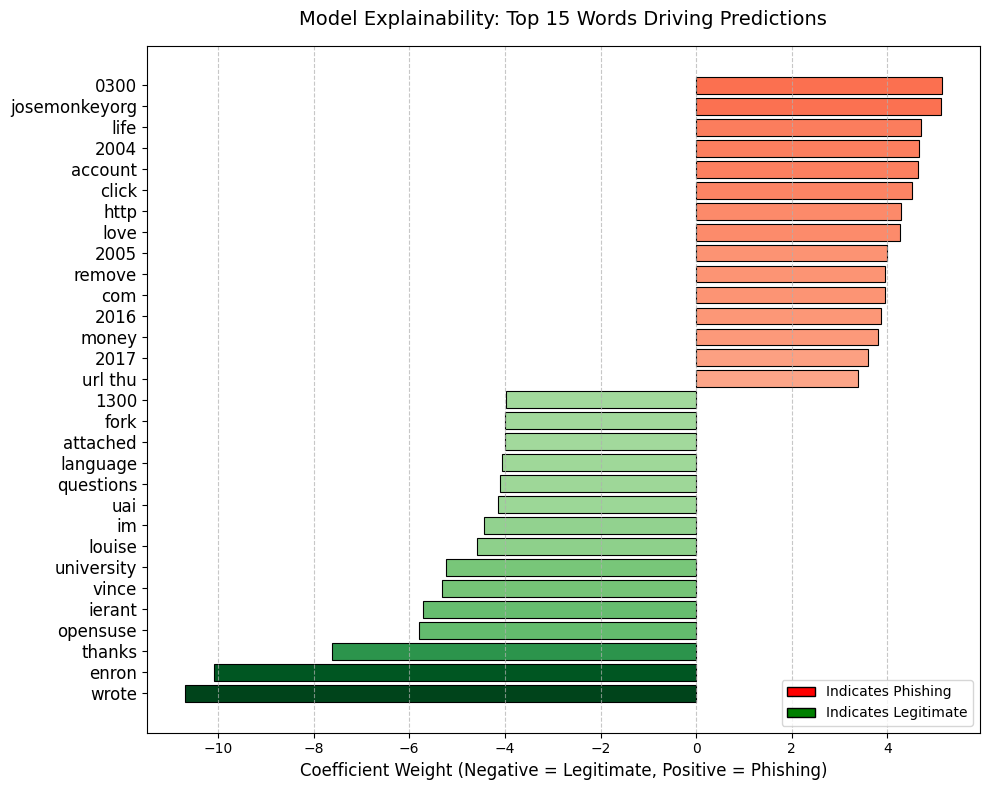

In [10]:
from matplotlib.patches import Patch

# get feature names and model coefficients
feature_names = np.array(vectorizer.get_feature_names_out())
coefs = model.coef_[0]

# top 15 phishing and top 15 legitimate indicators
top_phish_idx = coefs.argsort()[-15:]
top_legit_idx = coefs.argsort()[:15]

plot_indices = np.concatenate([top_legit_idx, top_phish_idx])
plot_words = feature_names[plot_indices]
plot_coefs = coefs[plot_indices]

# normalize absolute coefficient values for shading
norm = np.abs(plot_coefs) / np.max(np.abs(plot_coefs))

plt.figure(figsize=(10, 8))

for i, (coef, word) in enumerate(zip(plot_coefs, plot_words)):
    if coef < 0:
        # legitimate → green gradient
        color = plt.cm.Greens(norm[i])
    else:
        # phishing → red gradient
        color = plt.cm.Reds(norm[i])

    plt.barh(
        i,
        coef,
        color=color,
        edgecolor='black',   # border
        linewidth=0.8
    )

plt.yticks(np.arange(len(plot_words)), plot_words, fontsize=12)
plt.xlabel("Coefficient Weight (Negative = Legitimate, Positive = Phishing)", fontsize=12)
plt.title("Model Explainability: Top 15 Words Driving Predictions", fontsize=14, pad=15)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# custom legend
legend_elements = [
    Patch(facecolor='red', edgecolor='black', label='Indicates Phishing'),
    Patch(facecolor='green', edgecolor='black', label='Indicates Legitimate')
]
plt.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

In [11]:
# save the model and vectorizer for Week 7's comparison and UI development
import joblib

joblib.dump(model, 'baseline_model.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')

# save a small sample of the cleaned data for testing the UI later
df.sample(500, random_state=42).to_csv('cleaned_phishing_sample.csv', index=False)

print("Model, Vectorizer, and sample data successfully serialized for next checkpoint.")

Model, Vectorizer, and sample data successfully serialized for next checkpoint.


## 6. Limitations of the Baseline & Next Steps
While highly interpretable, this TF-IDF and Logistic Regression baseline has structural limitations:

- **Lack of Semantic Understanding**: TF-IDF cannot detect semantic similarity (e.g., “verify your account” vs. “confirm your credentials”).

- **Evasion Vulnerability**: It may miss obfuscated phishing patterns, homoglyph attacks, or highly targeted spear-phishing that mimics normal vocabulary.

- **Missing Context**: The model does not incorporate sender metadata, reply-chain context, or email headers.

**Week 7 Plan**: These limitations motivate our next step. We will introduce a neural model (e.g., a small Transformer like DistilBERT) capable of semantic understanding, and directly compare its performance and computational cost against this explainable baseline.